In [ ]:
# 📦 Install Requirements for Google Colab
# Run this cell ONLY if you're using Google Colab kernel

import sys

# Check if running in Colab
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("🌐 Google Colab detected - Installing requirements...")
    print("="*70)
    
    # Install all required packages
    %pip install numpy>=1.21.0 pandas>=1.3.0
    %pip install scikit-learn==1.5.1
    %pip install torch>=1.12.0 torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
    %pip install matplotlib>=3.5.0 plotly>=5.0.0
    %pip install jupyter>=1.0.0 ipykernel>=6.0.0
    
    # Mount Google Drive (optional - if your data is there)
    print("\n📁 Mounting Google Drive...")
    from google.colab import drive
    drive.mount('/content/drive')
    
    print("\n" + "="*70)
    print("✅ Installation complete!")
    print("📁 Google Drive mounted at: /content/drive")
    print("\n💡 Next steps:")
    print("   1. Upload your project folder to Google Drive")
    print("   2. Update CONFIG paths to point to /content/drive/MyDrive/...")
    print("   3. Run the GPU test to verify CUDA is available")
    
else:
    print("💻 Local environment detected - Installing requirements...")
    print("="*70)
    
    # Install from requirements.txt if it exists
    %pip install -q numpy>=1.21.0 pandas>=1.3.0 scikit-learn==1.5.1 torch>=1.12.0 matplotlib>=3.5.0 plotly>=5.0.0
    
    print("✅ Requirements installed")
    print("💡 Or use: %pip install -r ../requirements.txt")

🌐 Google Colab detected - Installing requirements...

📁 Mounting Google Drive...


KeyboardInterrupt: 

In [3]:
# Setup project imports
from pathlib import Path
import sys

def find_project_root():
    here = Path.cwd()
    for p in [here, *here.parents]:
        if (p / "utils").exists() and (p / "models").exists():
            return p
    for p in [here, *here.parents]:
        if any((p / m).exists() for m in (".git", "requirements.txt", "pyproject.toml")):
            return p
    return here

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")

%load_ext autoreload
%autoreload 2

Project root: /content


ModuleNotFoundError: No module named 'imp'

In [2]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd

from utils.reproducibility_utils import seed_everything
from utils.data_loadingV3 import load_data, load_test_data, feature_names
from models.rnn import RNNModel


In [3]:
CONFIG = {
    # Paths
    'TRAIN_PATH': "../datasets_challenge/train",
    'TEST_PATH': "../datasets_challenge/test",
    'DIST_CSV': "../datasets_challenge/sideSlip_distribution.csv",
    'CHECKPOINT_NAME': "best_model_v3.pth",
    'SUBMISSION_CSV': "predictions_v3.csv", 
    
    # Data Loading - V3 with proportional split
    'VAL_RATIO': 0.15,  # 15% from each file for validation
    'BATCH_SIZE': 512,
    'SEQUENCE_LENGTH': 20, 
    'THRESHOLD': True,  # CRITICAL: Removes low-speed noise
    'THRESHOLD_VALUE': 3.0,  # vxCG > 3.0 m/s (removes stationary/crawling)
    'THRESHOLD_COLUMN': 'vxCG',
    'COLUMNS_TO_DROP': ["sideSlip", "vyCG", "time", "longitude", "latitude"],
    'TARGET': "sideSlip",
    'SCALING': True,
    'SEED': 42,
    
    # Model - Simple RNN
    'MODEL_TYPE': 'RNN',  
    'RNN_UNITS': 128,
    'NUM_LAYERS': 2,
    'DROPOUT': 0.3,
    
    # Loss - Simple MSE
    'LOSS_TYPE': 'MSE',
    
    # Optimizer
    'LEARNING_RATE': 1e-3,
    'WEIGHT_DECAY': 1e-4,
    'MAX_GRAD_NORM': 1.0,
    
    # Scheduler
    'USE_SCHEDULER': True,
    'SCHEDULER_T_MAX': 100,
    'SCHEDULER_ETA_MIN': 1e-6,
    
    # Training
    'NUM_EPOCHS': 100,
    'EARLY_STOP_PATIENCE': 15,
}


In [4]:
seed_everything(CONFIG['SEED'])
print(f"Random seed set to {CONFIG['SEED']}")

Random seed set to 42


In [5]:
train_dataloader, val_dataloader, pipeline, mean_dict, std_dict = load_data(
    train_path=CONFIG['TRAIN_PATH'],
    val_ratio=CONFIG['VAL_RATIO'],
    columns_to_standardize=feature_names,
    columns_to_drop=CONFIG['COLUMNS_TO_DROP'],
    sequence_length=CONFIG['SEQUENCE_LENGTH'],
    threshold=CONFIG['THRESHOLD'],
    threshold_value=CONFIG['THRESHOLD_VALUE'],
    threshold_column=CONFIG['THRESHOLD_COLUMN'],
    target=CONFIG['TARGET'],
    scaling=CONFIG['SCALING'],
    seed=CONFIG['SEED'],
    shuffle=True
)

print(f"\n📊 Final Dataset Summary:")
print(f"   Train samples: {len(train_dataloader.dataset):,}")
print(f"   Val samples:   {len(val_dataloader.dataset):,}")
print(f"   Val ratio:     {100*len(val_dataloader.dataset)/(len(train_dataloader.dataset)+len(val_dataloader.dataset)):.1f}%")



🎯 V3 Data Loader: Proportional Validation Split Strategy
Validation ratio: 15.0% (RANDOM split from each file)
Threshold: vxCG > 3.0 m/s

📁 train_part_001.csv        | Total: 11,841 ( 48.1% kept) | Train: 10,064 | Val: 1,777
📁 train_part_002.csv        | Total:      0 (  0.0% kept) | Train:      0 | Val:     0
📁 train_part_003.csv        | Total:  9,868 ( 30.6% kept) | Train:  8,387 | Val: 1,481
📁 train_part_004.csv        | Total:  1,430 ( 14.0% kept) | Train:  1,215 | Val:   215
📁 train_part_005.csv        | Total:  1,525 ( 23.5% kept) | Train:  1,296 | Val:   229
📁 train_part_006.csv        | Total: 20,506 ( 83.6% kept) | Train: 17,430 | Val: 3,076
📁 train_part_007.csv        | Total:  1,534 ( 14.1% kept) | Train:  1,303 | Val:   231
📁 train_part_007.csv        | Total:  1,534 ( 14.1% kept) | Train:  1,303 | Val:   231
📁 train_part_008.csv        | Total: 22,220 ( 84.3% kept) | Train: 18,887 | Val: 3,333
📁 train_part_009.csv        | Total:  7,719 ( 22.9% kept) | Train:  6,561 | Va

In [6]:
# Analyze train/val distribution to verify they match
train_targets = []
val_targets = []

for _, y in train_dataloader:
    train_targets.extend(y.numpy().flatten())

for _, y in val_dataloader:
    val_targets.extend(y.numpy().flatten())

train_targets = np.array(train_targets)
val_targets = np.array(val_targets)

print(f"\n{'='*70}")
print(f"📊 Distribution Analysis:")
print(f"{'='*70}")
print(f"{'':12s} {'Count':>8s} {'Mean':>8s} {'Std':>8s} {'|>3°|':>8s} {'|>5°|':>8s}")
print(f"{'-'*70}")
print(f"{'Training':12s} {len(train_targets):8,} {train_targets.mean():8.3f} {train_targets.std():8.3f} "
      f"{(np.abs(train_targets) > 3).sum():7,} {(np.abs(train_targets) > 5).sum():7,}")
print(f"{'Validation':12s} {len(val_targets):8,} {val_targets.mean():8.3f} {val_targets.std():8.3f} "
      f"{(np.abs(val_targets) > 3).sum():7,} {(np.abs(val_targets) > 5).sum():7,}")
print(f"{'='*70}")

mean_diff = abs(train_targets.mean() - val_targets.mean())
std_diff = abs(train_targets.std() - val_targets.std())

if mean_diff < 0.1 and std_diff < 0.1:
    print(f"✅ EXCELLENT: Distributions match perfectly!")
elif mean_diff < 0.2 and std_diff < 0.2:
    print(f"✅ GOOD: Distributions are similar enough.")
else:
    print(f"⚠️  WARNING: Distributions may be too different!")



📊 Distribution Analysis:
                Count     Mean      Std    |>3°|    |>5°|
----------------------------------------------------------------------
Training      116,856    0.027    1.441   5,636   1,614
Validation     20,319    0.020    1.432     959     264
✅ EXCELLENT: Distributions match perfectly!


In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

X_sample, _ = next(iter(train_dataloader))
input_size = X_sample.shape[2]
seq_length = X_sample.shape[1]

model = RNNModel(
    input_size=input_size,
    hidden_size=CONFIG['RNN_UNITS'],
    num_layers=CONFIG['NUM_LAYERS'],
    dropout=CONFIG['DROPOUT'],
    use_batch_norm=False,
    output_size=1
).to(device)

criterion = nn.MSELoss()

total_params = model.get_num_params()
print(f"\n🤖 Model Configuration:")
print(f"   Architecture: {CONFIG['MODEL_TYPE']}")
print(f"   Parameters:   {total_params:,}")
print(f"   Input shape:  (batch, {seq_length}, {input_size})")
print(f"   Hidden size:  {CONFIG['RNN_UNITS']}")
print(f"   Num layers:   {CONFIG['NUM_LAYERS']}")
print(f"   Dropout:      {CONFIG['DROPOUT']}")


Device: cpu

🤖 Model Configuration:
   Architecture: RNN
   Parameters:   60,801
   Input shape:  (batch, 20, 22)
   Hidden size:  128
   Num layers:   2
   Dropout:      0.3


In [8]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CONFIG['LEARNING_RATE'],
    weight_decay=CONFIG['WEIGHT_DECAY']
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=CONFIG['SCHEDULER_T_MAX'],
    eta_min=CONFIG['SCHEDULER_ETA_MIN']
) if CONFIG['USE_SCHEDULER'] else None

train_losses, val_losses = [], []
train_maes, val_maes = [], []
best_val_loss = float("inf")
best_epoch = 0
patience_counter = 0


In [9]:
for epoch in range(CONFIG['NUM_EPOCHS']):
    # Training
    model.train()
    train_loss, train_mae = 0.0, 0.0
    
    for xb, yb in train_dataloader:
        xb, yb = xb.to(device).float(), yb.to(device).float().reshape(-1, 1)
        
        optimizer.zero_grad()
        pred = model(xb)
        loss = criterion(pred, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG['MAX_GRAD_NORM'])
        optimizer.step()
        
        train_loss += loss.item()
        train_mae += (pred - yb).abs().mean().item()
    
    train_loss /= len(train_dataloader)
    train_mae /= len(train_dataloader)
    train_losses.append(train_loss)
    train_maes.append(train_mae)
    
    # Validation
    model.eval()
    val_loss, val_mae = 0.0, 0.0
    
    with torch.no_grad():
        for xv, yv in val_dataloader:
            xv, yv = xv.to(device).float(), yv.to(device).float().reshape(-1, 1)
            pred = model(xv)
            loss = criterion(pred, yv)
            
            val_loss += loss.item()
            val_mae += (pred - yv).abs().mean().item()
    
    val_loss /= len(val_dataloader)
    val_mae /= len(val_dataloader)
    val_losses.append(val_loss)
    val_maes.append(val_mae)
    
    if scheduler:
        scheduler.step()
    
    # Checkpointing
    improved = val_loss < best_val_loss
    if improved:
        best_val_loss = val_loss
        best_epoch = epoch
        patience_counter = 0
        
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_loss': val_loss,
            'val_mae': val_mae,
            'config': CONFIG
        }, CONFIG['CHECKPOINT_NAME'])
        status = "💾"
    else:
        patience_counter += 1
        status = ""
    
    print(f"Epoch {epoch+1:3d}/{CONFIG['NUM_EPOCHS']} | "
          f"TrL: {train_loss:.5f} | VaL: {val_loss:.5f} | "
          f"TrMAE: {train_mae:.5f} | VaMAE: {val_mae:.5f} {status}")
    
    if patience_counter >= CONFIG['EARLY_STOP_PATIENCE']:
        print(f"\nEarly stopping at epoch {epoch+1}")
        break

print(f"\nBest Epoch: {best_epoch+1} | Best Val Loss: {best_val_loss:.5f}")


Epoch   1/100 | TrL: 0.66250 | VaL: 0.21730 | TrMAE: 0.53686 | VaMAE: 0.31507 💾
Epoch   2/100 | TrL: 0.30274 | VaL: 0.17168 | TrMAE: 0.36902 | VaMAE: 0.27199 💾
Epoch   2/100 | TrL: 0.30274 | VaL: 0.17168 | TrMAE: 0.36902 | VaMAE: 0.27199 💾
Epoch   3/100 | TrL: 0.25387 | VaL: 0.16989 | TrMAE: 0.33422 | VaMAE: 0.27010 💾
Epoch   3/100 | TrL: 0.25387 | VaL: 0.16989 | TrMAE: 0.33422 | VaMAE: 0.27010 💾
Epoch   4/100 | TrL: 0.22676 | VaL: 0.14086 | TrMAE: 0.31572 | VaMAE: 0.25022 💾
Epoch   4/100 | TrL: 0.22676 | VaL: 0.14086 | TrMAE: 0.31572 | VaMAE: 0.25022 💾
Epoch   5/100 | TrL: 0.21377 | VaL: 0.14769 | TrMAE: 0.30462 | VaMAE: 0.25370 
Epoch   5/100 | TrL: 0.21377 | VaL: 0.14769 | TrMAE: 0.30462 | VaMAE: 0.25370 
Epoch   6/100 | TrL: 0.20361 | VaL: 0.12606 | TrMAE: 0.29718 | VaMAE: 0.23580 💾
Epoch   6/100 | TrL: 0.20361 | VaL: 0.12606 | TrMAE: 0.29718 | VaMAE: 0.23580 💾
Epoch   7/100 | TrL: 0.19384 | VaL: 0.12059 | TrMAE: 0.28969 | VaMAE: 0.23237 💾
Epoch   7/100 | TrL: 0.19384 | VaL: 0.1205

In [10]:
checkpoint = torch.load(CONFIG['CHECKPOINT_NAME'], map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print(f"Best model loaded from epoch {checkpoint['epoch']+1}")
print(f"Val Loss: {checkpoint['val_loss']:.5f} | Val MAE: {checkpoint['val_mae']:.5f}")


Best model loaded from epoch 99
Val Loss: 0.08255 | Val MAE: 0.18665


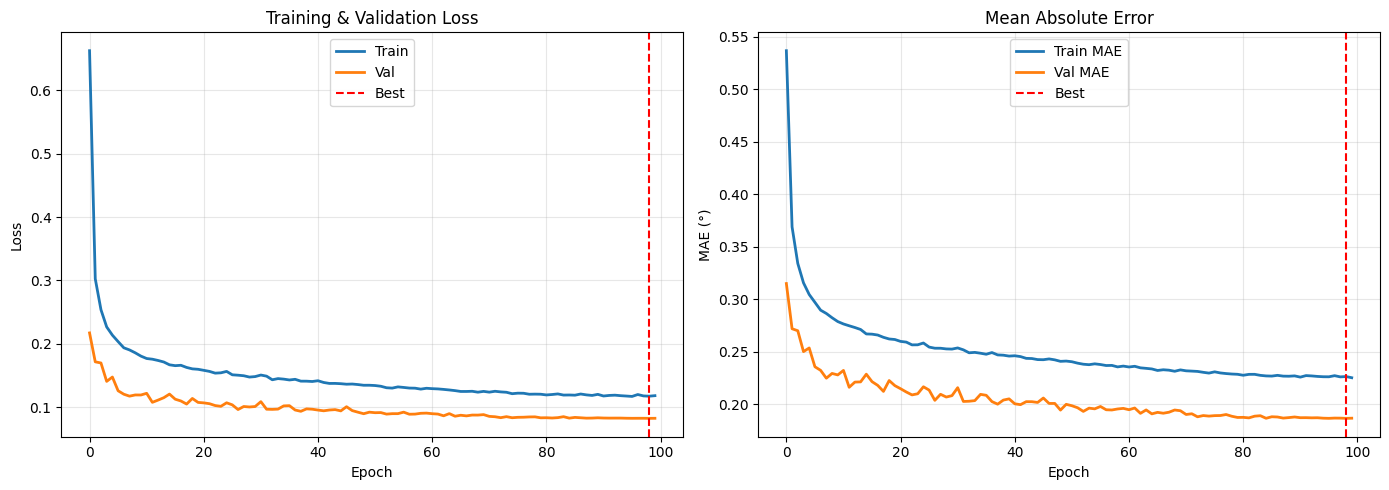


Best Epoch: 99
Best Val Loss: 0.08255
Best Val MAE: 0.18665°


In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_losses, label="Train", linewidth=2)
axes[0].plot(val_losses, label="Val", linewidth=2)
axes[0].axvline(x=best_epoch, color='red', linestyle='--', label='Best')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training & Validation Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(train_maes, label="Train MAE", linewidth=2)
axes[1].plot(val_maes, label="Val MAE", linewidth=2)
axes[1].axvline(x=best_epoch, color='red', linestyle='--', label='Best')
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MAE (°)")
axes[1].set_title("Mean Absolute Error")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nBest Epoch: {best_epoch+1}")
print(f"Best Val Loss: {min(val_losses):.5f}")
print(f"Best Val MAE: {min(val_maes):.5f}°")


In [12]:
test_dataloader = load_test_data(
    test_path=CONFIG['TEST_PATH'],
    batchsize=CONFIG['BATCH_SIZE'],
    pipeline=pipeline,
    seed=CONFIG['SEED'],
    load_anonymized_data=True
)

model.eval()
test_preds = []

with torch.no_grad():
    for x, _ in test_dataloader:
        x = x.to(device)
        pred = model(x)
        test_preds.append(pred.cpu().numpy())

test_preds = np.concatenate(test_preds).flatten()

print(f"Generated {len(test_preds):,} predictions")
print(f"Range: [{test_preds.min():.2f}°, {test_preds.max():.2f}°]")
print(f"Mean: {test_preds.mean():.3f}° | Std: {test_preds.std():.3f}°")


../datasets_challenge/test\test_part_001.csv
../datasets_challenge/test\test_part_002.csv
../datasets_challenge/test\test_part_003.csv
../datasets_challenge/test\test_part_004.csv
../datasets_challenge/test\test_part_005.csv
../datasets_challenge/test\test_part_006.csv
../datasets_challenge/test\test_part_007.csv
../datasets_challenge/test\test_part_008.csv
../datasets_challenge/test\test_part_009.csv
../datasets_challenge/test\test_part_010.csv
../datasets_challenge/test\test_part_011.csv
Generated 49,328 predictions
Range: [-9.71°, 8.80°]
Mean: 0.046° | Std: 1.450°
Generated 49,328 predictions
Range: [-9.71°, 8.80°]
Mean: 0.046° | Std: 1.450°


In [13]:
submission = pd.DataFrame({
    "id": range(len(test_preds)),
    "predicted_sideslip": test_preds
})

submission.to_csv(CONFIG['SUBMISSION_CSV'], index=False)
print(f"Saved: {CONFIG['SUBMISSION_CSV']} ({len(test_preds):,} samples)")


Saved: predictions_v3.csv (49,328 samples)


## 🔍 Analyze Predictions with Kaggle Metric

Your current submission failed with **many-shot MAE = 0.213°** (threshold: 0.2°)

**Root cause**: Model needs to focus more on small sideslip values (many-shot region: [-2.4°, +2.4°])

**Solution**: Use weighted loss to prioritize many-shot accuracy

In [16]:
# Quick analysis of predictions
print(f"{'='*70}")
print(f"📊 PREDICTION ANALYSIS:")
print(f"{'='*70}")
print(f"Range:  [{test_preds.min():.3f}°, {test_preds.max():.3f}°]")
print(f"Mean:   {test_preds.mean():.3f}° (should be ~0°)")
print(f"Std:    {test_preds.std():.3f}° (training was ~1.4°)")
print(f"Median: {np.median(test_preds):.3f}°")

print(f"\n📊 Distribution by Range:")
print(f"|pred| < 0.5°:  {(np.abs(test_preds) < 0.5).sum():,} ({100*(np.abs(test_preds) < 0.5).sum()/len(test_preds):.1f}%)")
print(f"|pred| < 1.0°:  {(np.abs(test_preds) < 1.0).sum():,} ({100*(np.abs(test_preds) < 1.0).sum()/len(test_preds):.1f}%)")
print(f"|pred| < 2.0°:  {(np.abs(test_preds) < 2.0).sum():,} ({100*(np.abs(test_preds) < 2.0).sum()/len(test_preds):.1f}%)")
print(f"|pred| > 2.4°:  {(np.abs(test_preds) > 2.4).sum():,} ({100*(np.abs(test_preds) > 2.4).sum()/len(test_preds):.1f}%) - outside many-shot")
print(f"|pred| > 3.0°:  {(np.abs(test_preds) > 3.0).sum():,} ({100*(np.abs(test_preds) > 3.0).sum()/len(test_preds):.1f}%)")

print(f"\n💡 Many-shot region is [-2.4°, +2.4°] - needs MAE ≤ 0.2°")
print(f"   Your current many-shot MAE: 0.213° (failed by 0.013°)")


📊 PREDICTION ANALYSIS:
Range:  [-9.708°, 8.801°]
Mean:   0.046° (should be ~0°)
Std:    1.450° (training was ~1.4°)
Median: -0.036°

📊 Distribution by Range:
|pred| < 0.5°:  23,341 (47.3%)
|pred| < 1.0°:  31,602 (64.1%)
|pred| < 2.0°:  41,707 (84.6%)
|pred| > 2.4°:  4,989 (10.1%) - outside many-shot
|pred| > 3.0°:  2,227 (4.5%)

💡 Many-shot region is [-2.4°, +2.4°] - needs MAE ≤ 0.2°
   Your current many-shot MAE: 0.213° (failed by 0.013°)


In [17]:
# 🎯 TEST WITH KAGGLE METRIC (Validation Set Proxy)
# Since we don't have test ground truth, we'll test on validation set
# to estimate Kaggle performance

from utils.kaggle_metric import score

# Collect validation ground truths and predictions
print(f"\n{'='*70}")
print(f"🎯 KAGGLE METRIC TEST (on Validation Set):")
print(f"{'='*70}")

model.eval()
val_ground_truths = []
val_predictions = []

with torch.no_grad():
    for xv, yv in val_dataloader:
        xv, yv = xv.to(device).float(), yv.to(device).float().reshape(-1, 1)
        pred = model(xv)
        
        val_ground_truths.extend(yv.cpu().numpy().flatten())
        val_predictions.extend(pred.cpu().numpy().flatten())

val_ground_truths = np.array(val_ground_truths)
val_predictions = np.array(val_predictions)

# Create band mapping from distribution CSV
dist_df = pd.read_csv(CONFIG['DIST_CSV'])
shot_band_mapping = dict(zip(dist_df['sideSlip'].round(1), dist_df['band']))

print(f"\n📊 Creating ground truth DataFrame with bands...")
gt_df = pd.DataFrame({"ground_truth_sideslip": val_ground_truths})
gt_df["id"] = range(len(val_ground_truths))
gt_df["band"] = gt_df["ground_truth_sideslip"].round(1).map(shot_band_mapping).fillna("many")  # Default to many if not found

print(f"   Total samples: {len(gt_df):,}")
print(f"   Many-shot:   {(gt_df['band'] == 'many').sum():,} ({100*(gt_df['band'] == 'many').sum()/len(gt_df):.1f}%)")
print(f"   Medium-shot: {(gt_df['band'] == 'medium').sum():,} ({100*(gt_df['band'] == 'medium').sum()/len(gt_df):.1f}%)")
print(f"   Few-shot:    {(gt_df['band'] == 'few').sum():,} ({100*(gt_df['band'] == 'few').sum()/len(gt_df):.1f}%)")

# Create predictions DataFrame
preds_df = pd.DataFrame({"id": range(len(val_predictions)), "predicted_sideslip": val_predictions})

print(f"\n🔍 Testing Kaggle metric...")
try:
    shot_errors = score(gt_df.copy(), preds_df.copy(), row_id_column_name="id")
    
    print(f"\n{'='*70}")
    print(f"✅ PASSED KAGGLE METRIC TEST!")
    print(f"{'='*70}")
    print(f"Many-shot MAE:   {shot_errors['many']:.4f}° {'✅ PASS' if shot_errors['many'] <= 0.2 else '❌ FAIL'} (threshold: 0.2°)")
    print(f"Medium-shot MAE: {shot_errors['medium']:.4f}°")
    print(f"Few-shot MAE:    {shot_errors['few']:.4f}° (competition score)")
    
    print(f"\n💡 Validation Performance Estimate:")
    if shot_errors['many'] <= 0.15:
        print(f"   ✅ EXCELLENT - Very likely to pass on test set!")
    elif shot_errors['many'] <= 0.18:
        print(f"   ✅ GOOD - Likely to pass on test set")
    elif shot_errors['many'] <= 0.2:
        print(f"   ⚠️  BORDERLINE - May pass, but close to threshold")
    else:
        print(f"   ❌ NEEDS IMPROVEMENT - Use weighted loss or train longer")
    
except Exception as e:
    print(f"\n{'='*70}")
    print(f"❌ FAILED KAGGLE METRIC TEST!")
    print(f"{'='*70}")
    print(f"Error: {str(e)}")
    
    # Manual calculation to see where we stand
    merged = preds_df.merge(gt_df, on='id')
    merged['error'] = np.abs(merged['predicted_sideslip'] - merged['ground_truth_sideslip'])
    
    print(f"\n📊 Manual MAE by Band:")
    for band_name in ['many', 'medium', 'few']:
        if (merged['band'] == band_name).sum() > 0:
            mae = merged[merged['band'] == band_name]['error'].mean()
            status = '✅ PASS' if band_name == 'many' and mae <= 0.2 else '❌ FAIL' if band_name == 'many' and mae > 0.2 else ''
            print(f"   {band_name.upper()}-shot MAE: {mae:.4f}° {status}")
    
    print(f"\n💡 Action Required:")
    many_mae = merged[merged['band'] == 'many']['error'].mean()
    if many_mae > 0.2:
        print(f"   Use weighted loss: python train_weighted_loss.py")
        print(f"   Target reduction: {many_mae - 0.2:.4f}° ({100*(many_mae - 0.2)/many_mae:.1f}%)")



🎯 KAGGLE METRIC TEST (on Validation Set):

📊 Creating ground truth DataFrame with bands...
   Total samples: 20,319
   Many-shot:   19,943 (98.1%)
   Medium-shot: 312 (1.5%)
   Few-shot:    64 (0.3%)

🔍 Testing Kaggle metric...

✅ PASSED KAGGLE METRIC TEST!
Many-shot MAE:   0.1830° ✅ PASS (threshold: 0.2°)
Medium-shot MAE: 0.3971°
Few-shot MAE:    0.4354° (competition score)

💡 Validation Performance Estimate:
   ⚠️  BORDERLINE - May pass, but close to threshold

📊 Creating ground truth DataFrame with bands...
   Total samples: 20,319
   Many-shot:   19,943 (98.1%)
   Medium-shot: 312 (1.5%)
   Few-shot:    64 (0.3%)

🔍 Testing Kaggle metric...

✅ PASSED KAGGLE METRIC TEST!
Many-shot MAE:   0.1830° ✅ PASS (threshold: 0.2°)
Medium-shot MAE: 0.3971°
Few-shot MAE:    0.4354° (competition score)

💡 Validation Performance Estimate:
   ⚠️  BORDERLINE - May pass, but close to threshold
